# Monthly temperature threshold climatologies from ERA5 (solved)
### Frost days, summer days and tropical nights at a location of your choice

**Author**: Matthew Menary (ECMWF)

## About

This notebook is adapted from the ERA Explorer notebook [Calculate the monthly climatological temperature thresholds from ERA5](https://era-explorer.climate.copernicus.eu/notebooks/content/temperature/temperature_monthly_thresholds_climatology.html), by Matthew Menary (ECMWF), © 2023 ECMWF. It is used in Module 8, *Advanced use of climate data and C3S tools*, of the [*Understanding Climate Data*](https://climate.copernicus.eu/online-course-understanding-climate-data) online course of the Copernicus Climate Change Service (C3S).

## Running this notebook

This is the **solved version** of the notebook: all the code has already been run, so you can read the outputs (figures, tables and printed results) without running anything.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/isaldiviagonzatti/2027-c3s-climate-data-m8/blob/main/temperature_monthly_thresholds_climatology_solved.ipynb)

To run the notebook yourself, open the [original version](https://colab.research.google.com/github/isaldiviagonzatti/2027-c3s-climate-data-m8/blob/main/temperature_monthly_thresholds_climatology.ipynb) in Google Colab. To keep your own changes, use **File > Save a copy in Drive** once the notebook is open in Colab.

## Introduction

A **climate index** describes one aspect of the climate with a single number. Many indices count how often a variable crosses a threshold. In this notebook we calculate three of them:

- **Frost days**: days when the daily minimum temperature is below 0 °C.
- **Summer days**: days when the daily maximum temperature is above 25 °C.
- **Tropical nights**: days when the daily minimum temperature is above 20 °C.

For each month of the year, we calculate the average percentage of days that meet each threshold over the reference period 1991–2020. This is the same information shown in the [ERA Explorer](https://era-explorer.climate.copernicus.eu/) application of C3S.

**Data**: hourly 2 m temperature from the [ERA5 hourly time-series data on single levels](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries) dataset of the Copernicus Climate Data Store (CDS). This dataset provides ERA5 time series at a single grid point, so the download is small and fast.

In this notebook you will:

1. Download a 30-year time series of hourly ERA5 temperature for one location using [`earthkit-data`](https://earthkit-data.readthedocs.io/).
2. Calculate daily minimum and maximum temperatures.
3. Count frost days, summer days and tropical nights, and average them per month.
4. Plot the monthly climatology of each index.

The default location is Brussels, Belgium. You can change it to any location in the world.

For further training material, see the [C3S data tutorials](https://ecmwf-projects.github.io/copernicus-training-c3s/intro.html).

### Before you start: get access to the data

The data are downloaded from the Copernicus [Climate Data Store (CDS)](https://cds.climate.copernicus.eu). You need:

1. A free ECMWF account. Register or log in at the [Climate Data Store (CDS)](https://cds.climate.copernicus.eu).
2. To accept the licence of the dataset [ERA5 hourly time-series data on single levels from 1940 to present](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries). Open the dataset page, go to the **Download** tab and accept the terms of use at the bottom of the page. You only need to do this once.
3. Your **personal access token**. You can find it on your profile page once you are logged in (see the [API how-to page](https://cds.climate.copernicus.eu/how-to-api)).

The notebook will ask you to paste your token when it needs it. The token is not shown on screen and is not saved in the notebook.

---
## Prepare your environment

This notebook uses:
- `earthkit-data` and `cdsapi` to download the data from the CDS
- `pandas` to process the time series
- `matplotlib` to plot the results

Google Colab already includes `pandas` and `matplotlib`. Run the cell below to install the other packages. This may take a minute.

In [1]:
%pip install -q earthkit-data cdsapi

In [2]:
import os
from getpass import getpass
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import calendar
import earthkit.data

### Enter your CDS access token

The cell below asks for your CDS personal access token and keeps it for this session only. If you run the notebook on your own computer and have already set up a `.cdsapirc` file, the cell uses that file and does not ask for the token.

In [3]:
CDS_URL = "https://cds.climate.copernicus.eu/api"

# earthkit-data uses the CDS API settings from a ~/.cdsapirc file or from
# the CDSAPI_URL and CDSAPI_KEY environment variables.
if not (Path.home() / ".cdsapirc").exists():
    os.environ.setdefault("CDSAPI_URL", CDS_URL)
    if not os.environ.get("CDSAPI_KEY"):
        os.environ["CDSAPI_KEY"] = getpass("Enter your CDS personal access token: ")

## Choose the location, variable and period

This is the latitude/longitude that we will extract the nearest grid cell from. You can change these to plot different locations. You can see the currently used ones in the ERA Explorer URL. In this example we are plotting data at the gridpoint closest to Brussels, Belgium. 

In [4]:
lat = 50.86
lng = 4.35

This is the variable we are getting from the ERA dataset, and the time period

In [5]:
variable = "2m_temperature"
date_range = ["1991-01-01", "2020-12-31"]

For convenience, we make a function to handle the data retrieval:

In [6]:
def retrieve_data(variable, date_range, lat, lng):
    # Define the dataset and request parameters
    dataset = "reanalysis-era5-single-levels-timeseries"
    request = {
        "variable": [
        variable,  # Variable to retrieve
        ],
        "date": date_range,  # Date range for the data
        "location": {"longitude": lng, "latitude": lat},  # Location coordinates
        "data_format": "netcdf"  # Format of the retrieved data
    }

    # Use "earthkit" to retrieve the data
    ekds = earthkit.data.from_source(
        "cds", dataset, request
    ).to_xarray()

    return ekds

Get the data. This will download a NetCDF file

In [7]:
data = retrieve_data(variable, date_range, lat, lng)

2026-11-21 19:36:45,462 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-21 19:36:46,029 INFO Request ID is 31000001-b16e-4d41-b0aa-08bde9cacaa7
2026-11-21 19:36:46,098 INFO status has been updated to accepted
2026-11-21 19:37:07,347 INFO status has been updated to running
2026-11-21 19:37:18,787 INFO status has been updated to successful


And let's make some bespoke functions to process the data. Each one is described with a """`docstring`"""

In [8]:
# Make a function to compute the monthly temperature climatology
def temperatureMonthlyClimatology():
    """
    Processes temperature data to calculate monthly climatology and thresholds.

    This function reads temperature data from a NetCDF file, processes it to calculate
    daily minimum and maximum temperatures, and then computes monthly climatology
    statistics. It also calculates the percentage of frost days, tropical nights, and
    summer days per month over a 30-year period.

    Returns:
        tuple: A tuple containing the following elements:
            - monthly_climatology (pd.DataFrame): Climatological averages for daily 
              minimum and maximum temperatures per month, converted to Celsius.
            - frost_day_climatology (pd.Series): Average percentage of frost days
              per month.
            - tropical_night_climatology (pd.Series): Average percentage of tropical 
              nights per month.
            - summer_day_climatology (pd.Series): Average percentage of summer days
              per month.
    """
        
    data_t2m_pt = data.t2m

    # Convert the time coordinate to a pandas datetime index
    time_index = pd.to_datetime(data_t2m_pt.valid_time.values)
    
    # Create a DataFrame for easier manipulation
    df = pd.DataFrame(data_t2m_pt.values, index=time_index, columns=['t2m'])
    
    # Resample to find daily minimum and maximum
    daily_min = df.resample('D').min()
    daily_max = df.resample('D').max()
    
    # Combine the daily min and max into a single DataFrame
    daily_stats = pd.DataFrame({
        'daily_min': daily_min['t2m'],
        'daily_max': daily_max['t2m']
    })

    # Define the frost night threshold (e.g., 0°C in Kelvin)
    frostDayThreshold = 0 + 273.15
    tropicalNightThreshold = 20 + 273.15
    summerDayThreshold = 25 + 273.15
    
    # Check if the daily minimum is below the threshold
    daily_min['frost_day'] = daily_min['t2m'] < frostDayThreshold
    daily_min['tropical_night'] = daily_min['t2m'] > tropicalNightThreshold
    daily_max['summer_day'] = daily_max['t2m'] > summerDayThreshold
    
    # Count the number of frost days (days below the threshold) per month
    frost_day_counts = daily_min.resample('ME').sum()['frost_day']
    tropical_night_counts = daily_min.resample('ME').sum()['tropical_night']
    summer_day_counts = daily_max.resample('ME').sum()['summer_day']

    # Count the total number of days per month
    total_days_per_month = daily_min.resample('ME').size()

    # Calculate the percentage of frost nights per month
    frost_day_pc = (frost_day_counts / total_days_per_month) * 100
    tropical_night_pc = (tropical_night_counts / total_days_per_month) * 100
    summer_day_pc = (summer_day_counts / total_days_per_month) * 100
    
    # Convert the index to month
    frost_day_pc.index = frost_day_pc.index.month
    tropical_night_pc.index = tropical_night_pc.index.month
    summer_day_pc.index = summer_day_pc.index.month
    
    # Group by month and calculate the average percentage over the 30-year period
    frost_day_climatology = frost_day_pc.groupby(frost_day_pc.index).mean()
    tropical_night_climatology = tropical_night_pc.groupby(tropical_night_pc.index).mean()
    summer_day_climatology = summer_day_pc.groupby(summer_day_pc.index).mean()

    # Extract the month from DateTimeIndex
    daily_stats['month'] = daily_stats.index.month
    
    # Group by month and calculate climatological averages for daily min and max
    grouped_by_month = daily_stats.groupby('month')
    monthly_climatology = grouped_by_month.mean() - 273.15  # Convert to Celsius

    # Get the actual lat/lon used
    nearest_lat = data_t2m_pt.latitude.values
    nearest_lng = data_t2m_pt.longitude.values
    
    return monthly_climatology, frost_day_climatology, \
           tropical_night_climatology, summer_day_climatology, \
           nearest_lat, nearest_lng

# Call our function
clim, frost_clim, tropical_clim, summer_clim, \
  nearest_lat, nearest_lng = temperatureMonthlyClimatology()

And finally, let's set up the plot nicely. This can easily be customised, but for now we do something similar to [ERA Explorer](https://era-explorer.climate.copernicus.eu/)

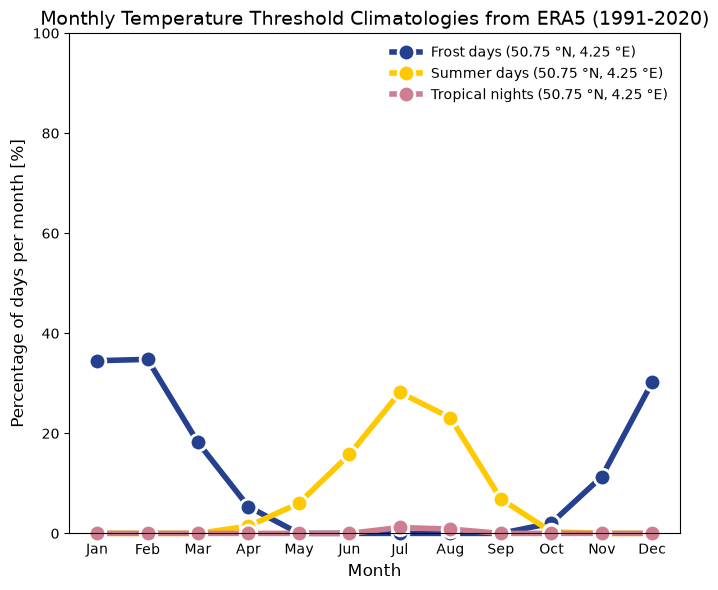

In [9]:
# Set line width, marker properties, and edge properties for the plot
lw = 4  # Line width for the plot lines
marker = 'o'  # Marker style for the data points
markersize = 12  # Size of the markers
markeredgecolor = 'white'  # Color of the marker edges
markeredgewidth = 2  # Width of the marker edges

# Determine the suffix for latitude (N/S) and longitude (E/W) based on their signs
latSuffix = 'N' if nearest_lat > 0 else 'S'
lngSuffix = 'E' if nearest_lng > 0 else 'W'

# Create a new figure with specified size
plt.figure(figsize=(7, 6))

# Plot frost days climatology with customized markers and lines
plt.plot(
    clim.index,
    frost_clim,
    marker=marker,
    markersize=markersize,
    markeredgecolor=markeredgecolor,
    markeredgewidth=markeredgewidth,
    label=(
        f'Frost days ({abs(nearest_lat):.2f} °{latSuffix}, '
        f'{abs(nearest_lng):.2f} °{lngSuffix})'
    ),
    color='#25408F',
    lw=lw,
    clip_on=False
)

# Plot summer days climatology with the same styling as frost days
plt.plot(
    clim.index,
    summer_clim,
    marker=marker,
    markersize=markersize,
    markeredgecolor=markeredgecolor,
    markeredgewidth=markeredgewidth,
    label=(
        f'Summer days ({abs(nearest_lat):.2f} °{latSuffix}, '
        f'{abs(nearest_lng):.2f} °{lngSuffix})'
    ),
    color='#FFC900',
    lw=lw,
    clip_on=False
)

# Plot tropical nights climatology with the same styling as other plots
plt.plot(
    clim.index,
    tropical_clim,
    marker=marker,
    markersize=markersize,
    markeredgecolor=markeredgecolor,
    markeredgewidth=markeredgewidth,
    label=(
        f'Tropical nights ({abs(nearest_lat):.2f} °{latSuffix}, '
        f'{abs(nearest_lng):.2f} °{lngSuffix})'
    ),
    color='#CF7E92',
    lw=lw,
    clip_on=False
)

# Add legend to the plot with no background frame
plt.legend(framealpha=0)

# Customize x and y axis labels
plt.xlabel('Month', fontsize=12)
plt.ylabel('Percentage of days per month [%]', fontsize=12)

# Set x-axis ticks to correspond to month indices and display month abbreviations
plt.xticks(
    ticks=clim.index,
    labels=[calendar.month_abbr[i] for i in clim.index]
)

# Set the limits for the y-axis to range from 0 to 100
plt.ylim(0, 100)

# Add a title with the specified date range and custom font size
plt.title(
    f'Monthly Temperature Threshold Climatologies from ERA5 '
    f'({date_range[0][:4]}-{date_range[1][:4]})',
    fontsize=14
)

# Adjust layout to ensure all elements are properly displayed and do not overlap
plt.tight_layout()

# Display the final plot
plt.show()